### Recent History Models Comparison

##### 1. Load and prepare the monthly series


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# =========================================================
# LOAD DATA
# =========================================================

d = pd.read_csv("Inventory_Turnover.csv")

d["dispense_date"] = pd.to_datetime(
    d["dispense_date"],
    dayfirst=True,
    format="mixed"
)

# Monthly total quantity dispensed
monthly = (
    d.set_index("dispense_date")["qty_dispensed"]
    .resample("ME")
    .sum()
    .astype(float)
)

monthly = monthly.asfreq("ME")

print("Monthly observations:")
print(monthly)

print("\nNumber of observations:", len(monthly))

Monthly observations:
dispense_date
2022-02-28     2947.0
2022-03-31    15283.0
2022-04-30    14378.0
2022-05-31    14793.0
2022-06-30    15607.0
2022-07-31    17530.0
2022-08-31    18077.0
2022-09-30    15119.0
2022-10-31    17266.0
2022-11-30    19581.0
2022-12-31    19943.0
2023-01-31    15702.0
2023-02-28     8068.0
2023-03-31     9356.0
2023-04-30     9330.0
2023-05-31    10054.0
2023-06-30    10001.0
2023-07-31    10401.0
2023-08-31    10796.0
2023-09-30     9865.0
2023-10-31    10546.0
2023-11-30    11379.0
2023-12-31    12053.0
2024-01-31    10567.0
2024-02-29     8886.0
Freq: ME, Name: qty_dispensed, dtype: float64

Number of observations: 25


##### 2. Define the candidate forecasting models

In [2]:
from statsmodels.tsa.holtwinters import Holt


# =========================================================
# FORECASTING FUNCTIONS
# =========================================================

def forecast_naive(train):
    """
    Forecast next month using the most recent month.
    """
    return train.iloc[-1]


def forecast_ma3(train):
    """
    Forecast next month using the average of
    the most recent 3 months.
    """
    if len(train) < 3:
        return np.nan

    return train.iloc[-3:].mean()


def forecast_ma6(train):
    """
    Forecast next month using the average of
    the most recent 6 months.
    """
    if len(train) < 6:
        return np.nan

    return train.iloc[-6:].mean()


def forecast_weighted_ma3(train):
    """
    Weighted moving average.

    Most recent month gets the highest weight.
    Weights:
        oldest = 1
        middle = 2
        newest = 3
    """
    if len(train) < 3:
        return np.nan

    last3 = train.iloc[-3:].values

    weights = np.array([1, 2, 3])

    return np.average(last3, weights=weights)


def forecast_ses(train):
    """
    Simple Exponential Smoothing.
    """
    try:
        model = SimpleExpSmoothing(
            train,
            initialization_method="estimated"
        ).fit(
            optimized=True
        )

        return model.forecast(1).iloc[0]

    except Exception:
        return np.nan


def forecast_holt(train):
    """
    Holt linear trend.
    """
    try:
        model = Holt(
            train,
            initialization_method="estimated"
        ).fit(
            optimized=True
        )

        return model.forecast(1).iloc[0]

    except Exception:
        return np.nan


def forecast_holt_damped(train):
    """
    Holt damped trend.
    """
    try:
        model = Holt(
            train,
            damped_trend=True,
            initialization_method="estimated"
        ).fit(
            optimized=True
        )

        return model.forecast(1).iloc[0]

    except Exception:
        return np.nan

##### 3. Run rolling-origin validation

In [3]:
# =========================================================
# MODEL LIST
# =========================================================

models = {
    "Naive": forecast_naive,
    "MA 3": forecast_ma3,
    "MA 6": forecast_ma6,
    "Weighted MA 3": forecast_weighted_ma3,
    "Simple Exponential Smoothing": forecast_ses,
    "Holt Additive": forecast_holt,
    "Holt Damped": forecast_holt_damped
}


# =========================================================
# ROLLING-ORIGIN VALIDATION
# =========================================================

initial_train_size = 12

validation_results = []

for i in range(initial_train_size, len(monthly)):

    train = monthly.iloc[:i]

    forecast_date = monthly.index[i]

    actual = monthly.iloc[i]

    for model_name, forecast_function in models.items():

        prediction = forecast_function(train)

        validation_results.append({
            "Model": model_name,
            "Forecast_Date": forecast_date,
            "Actual": actual,
            "Prediction": prediction
        })


validation_results = pd.DataFrame(validation_results)

validation_results = validation_results.dropna(
    subset=["Prediction"]
)

print(validation_results)

c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to co

                           Model Forecast_Date  Actual    Prediction
0                          Naive    2023-02-28  8068.0  15702.000000
1                           MA 3    2023-02-28  8068.0  18408.666667
2                           MA 6    2023-02-28  8068.0  17614.666667
3                  Weighted MA 3    2023-02-28  8068.0  17762.166667
4   Simple Exponential Smoothing    2023-02-28  8068.0  17234.667719
..                           ...           ...     ...           ...
86                          MA 6    2024-02-29  8886.0  10867.666667
87                 Weighted MA 3    2024-02-29  8886.0  11197.666667
88  Simple Exponential Smoothing    2024-02-29  8886.0  10567.000022
89                 Holt Additive    2024-02-29  8886.0  10952.378788
90                   Holt Damped    2024-02-29  8886.0  11100.088757

[91 rows x 4 columns]


c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
c:\Users\rob_m\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


##### 4. Calculate the validation errors

In [4]:
# =========================================================
# ERROR METRICS
# =========================================================

validation_results["Error"] = (
    validation_results["Actual"]
    - validation_results["Prediction"]
)

validation_results["Absolute_Error"] = (
    validation_results["Error"].abs()
)

validation_results["Squared_Error"] = (
    validation_results["Error"] ** 2
)

validation_results["APE"] = (
    validation_results["Absolute_Error"]
    / validation_results["Actual"]
    * 100
)

validation_results["sMAPE"] = (
    2
    * validation_results["Absolute_Error"]
    / (
        validation_results["Actual"].abs()
        + validation_results["Prediction"].abs()
    )
    * 100
)

##### 5. Produce the model comparison

In [5]:
# =========================================================
# MODEL COMPARISON
# =========================================================

comparison = (
    validation_results
    .groupby("Model")
    .agg(
        MAE=("Absolute_Error", "mean"),
        RMSE=(
            "Squared_Error",
            lambda x: np.sqrt(x.mean())
        ),
        MAPE=("APE", "mean"),
        sMAPE=("sMAPE", "mean"),
        Forecasts=("Actual", "count")
    )
    .reset_index()
)

comparison = comparison.sort_values("MAE")

print("\nMODEL COMPARISON")
print("=" * 80)

print(
    comparison.round({
        "MAE": 2,
        "RMSE": 2,
        "MAPE": 2,
        "sMAPE": 2
    }).to_string(index=False)
)


MODEL COMPARISON
                       Model     MAE    RMSE  MAPE  sMAPE  Forecasts
                       Naive 1292.77 2292.01 14.28  11.88         13
Simple Exponential Smoothing 1438.19 2698.34 15.97  12.75         13
               Weighted MA 3 1722.10 2984.42 19.09  15.06         13
                        MA 3 2033.85 3388.52 22.48  17.46         13
               Holt Additive 2325.05 4407.57 25.94  19.34         13
                 Holt Damped 2337.68 4249.33 26.14  19.94         13
                        MA 6 2635.63 3856.63 28.55  22.09         13


##### 6. Show every rolling forecast

In [6]:
# =========================================================
# INDIVIDUAL FORECASTS
# =========================================================

forecast_detail = validation_results[
    [
        "Forecast_Date",
        "Model",
        "Actual",
        "Prediction",
        "Error",
        "Absolute_Error",
        "APE"
    ]
].copy()

forecast_detail = forecast_detail.sort_values(
    ["Forecast_Date", "Model"]
)

print(
    forecast_detail.round(2).to_string(index=False)
)

Forecast_Date                        Model  Actual  Prediction     Error  Absolute_Error    APE
   2023-02-28                Holt Additive  8068.0    23160.05 -15092.05        15092.05 187.06
   2023-02-28                  Holt Damped  8068.0    22229.87 -14161.87        14161.87 175.53
   2023-02-28                         MA 3  8068.0    18408.67 -10340.67        10340.67 128.17
   2023-02-28                         MA 6  8068.0    17614.67  -9546.67         9546.67 118.33
   2023-02-28                        Naive  8068.0    15702.00  -7634.00         7634.00  94.62
   2023-02-28 Simple Exponential Smoothing  8068.0    17234.67  -9166.67         9166.67 113.62
   2023-02-28                Weighted MA 3  8068.0    17762.17  -9694.17         9694.17 120.16
   2023-03-31                Holt Additive  9356.0    10695.32  -1339.32         1339.32  14.32
   2023-03-31                  Holt Damped  9356.0    12320.84  -2964.84         2964.84  31.69
   2023-03-31                         MA

##### 7. Identify the winning model

In [7]:
# =========================================================
# BEST MODEL
# =========================================================

best_models = (
    comparison
    .sort_values("MAE", ignore_index=True)
    .iloc[:4][["Model", "MAE"]]
)

best_model_name = best_models.iloc[0, 0]

print("\nBest models based on rolling-origin MAE:")
print(best_models.round(2))


Best models based on rolling-origin MAE:
                          Model      MAE
0                         Naive  1292.77
1  Simple Exponential Smoothing  1438.19
2                 Weighted MA 3  1722.10
3                          MA 3  2033.85


##### 8. Create the final forecasting function

In [8]:
# =========================================================
# FINAL MODEL FORECAST
# =========================================================

def fit_final_model(model_name, series):

    if model_name == "Naive":

        return None

    elif model_name == "MA 3":

        return None

    elif model_name == "MA 6":

        return None

    elif model_name == "Weighted MA 3":

        return None

    elif model_name == "Simple Exponential Smoothing":

        model = SimpleExpSmoothing(
            series,
            initialization_method="estimated"
        ).fit(
            optimized=True
        )

        return model

    elif model_name == "Holt Additive":

        model = Holt(
            series,
            initialization_method="estimated"
        ).fit(
            optimized=True
        )

        return model

    elif model_name == "Holt Damped":

        model = Holt(
            series,
            damped_trend=True,
            initialization_method="estimated"
        ).fit(
            optimized=True
        )

        return model

    else:
        raise ValueError(
            f"Unknown model: {model_name}"
        )

##### 9. Generate 3-, 6-, and 12-month forecasts

In [9]:
# =========================================================
# MULTI-STEP FORECAST
# =========================================================

def multi_step_forecast(series, model_name, horizon):

    history = list(series.values)

    # ---------------------------------------------
    # Models requiring recursive forecasting
    # ---------------------------------------------

    if model_name in [
        "Naive",
        "MA 3",
        "MA 6",
        "Weighted MA 3"
    ]:

        forecasts = []

        for _ in range(horizon):

            history_series = pd.Series(history)

            if model_name == "Naive":

                prediction = history_series.iloc[-1]

            elif model_name == "MA 3":

                prediction = history_series.iloc[-3:].mean()

            elif model_name == "MA 6":

                prediction = history_series.iloc[-6:].mean()

            elif model_name == "Weighted MA 3":

                last3 = history_series.iloc[-3:].values

                weights = np.array([1, 2, 3])

                prediction = np.average(
                    last3,
                    weights=weights
                )

            forecasts.append(prediction)

            # Add prediction to history
            history.append(prediction)

        return np.array(forecasts)

    # ---------------------------------------------
    # Exponential smoothing / Holt models
    # ---------------------------------------------

    else:

        model = fit_final_model(
            model_name,
            series
        )

        return np.asarray(
            model.forecast(horizon)
        )

In [10]:
# =========================================================
# FORECAST 3, 6, AND 12 MONTHS
# =========================================================

forecast_3 = multi_step_forecast(
    monthly,
    best_model_name,
    3
)

forecast_6 = multi_step_forecast(
    monthly,
    best_model_name,
    6
)

forecast_12 = multi_step_forecast(
    monthly,
    best_model_name,
    12
)

##### 10. Create the forecast table

In [11]:
# =========================================================
# FORECAST TABLE
# =========================================================

last_date = monthly.index[-1]

forecast_dates = pd.date_range(
    start=last_date + pd.offsets.MonthEnd(1),
    periods=12,
    freq="ME"
)

forecast_values = forecast_12

forecast_table = pd.DataFrame({
    "Month": forecast_dates,
    "Forecast_Qty": forecast_values
})

forecast_table["Forecast_Qty"] = (
    forecast_table["Forecast_Qty"]
    .round()
    .astype(int)
)

# Add forecast horizon
forecast_table["Horizon"] = (
    np.arange(1, 13)
)

print("\n12-MONTH FORECAST")
print("=" * 60)

print(
    forecast_table[
        ["Horizon", "Month", "Forecast_Qty"]
    ].to_string(index=False)
)


12-MONTH FORECAST
 Horizon      Month  Forecast_Qty
       1 2024-03-31          8886
       2 2024-04-30          8886
       3 2024-05-31          8886
       4 2024-06-30          8886
       5 2024-07-31          8886
       6 2024-08-31          8886
       7 2024-09-30          8886
       8 2024-10-31          8886
       9 2024-11-30          8886
      10 2024-12-31          8886
      11 2025-01-31          8886
      12 2025-02-28          8886


##### 11. Create separate 3-, 6-, and 12-month summary

In [12]:
# =========================================================
# FORECAST SUMMARY
# =========================================================

summary = pd.DataFrame({
    "Horizon": [
        "3 months",
        "6 months",
        "12 months"
    ],
    "Total_Forecast_Qty": [
        forecast_3.sum(),
        forecast_6.sum(),
        forecast_12.sum()
    ],
    "Average_Monthly_Forecast": [
        forecast_3.mean(),
        forecast_6.mean(),
        forecast_12.mean()
    ]
})

summary["Total_Forecast_Qty"] = (
    summary["Total_Forecast_Qty"]
    .round()
    .astype(int)
)

summary["Average_Monthly_Forecast"] = (
    summary["Average_Monthly_Forecast"]
    .round()
    .astype(int)
)

print("\nFORECAST SUMMARY")
print("=" * 60)

print(summary.to_string(index=False))


FORECAST SUMMARY
  Horizon  Total_Forecast_Qty  Average_Monthly_Forecast
 3 months               26658                      8886
 6 months               53316                      8886
12 months              106632                      8886


##### 12. Plot the historical data and forecast

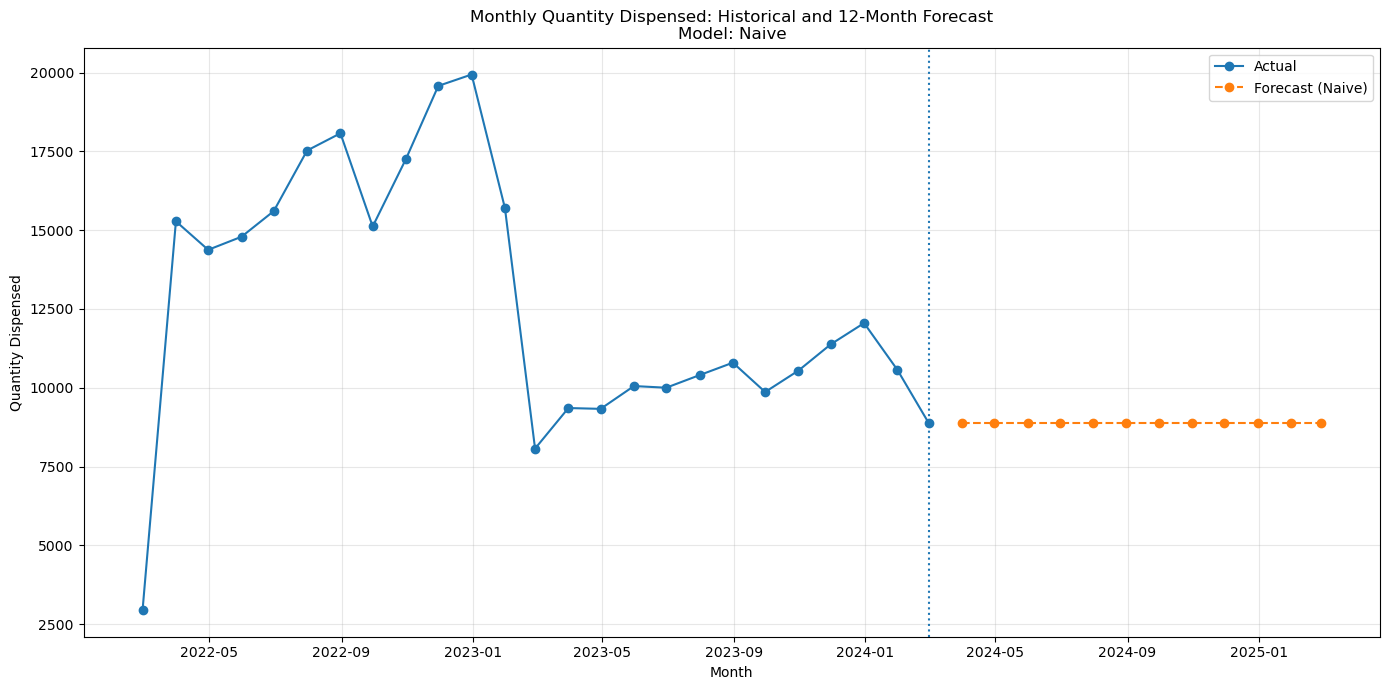

In [13]:
# =========================================================
# FORECAST PLOT
# =========================================================

plt.figure(figsize=(14, 7))

# Historical actuals
plt.plot(
    monthly.index,
    monthly.values,
    marker="o",
    label="Actual"
)

# Forecast
plt.plot(
    forecast_table["Month"],
    forecast_table["Forecast_Qty"],
    marker="o",
    linestyle="--",
    label=f"Forecast ({best_model_name})"
)

# Forecast starting point
plt.axvline(
    x=monthly.index[-1],
    linestyle=":"
)

plt.title(
    f"Monthly Quantity Dispensed: "
    f"Historical and 12-Month Forecast\n"
    f"Model: {best_model_name}"
)

plt.xlabel("Month")
plt.ylabel("Quantity Dispensed")

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

##### 13. One additional plot 

Naive MAE: 1292.77
SES MAE:   1410.67
             Actual  Naive Forecast  SES Forecast  SES Converged
Date                                                            
2023-10-31  10546.0          9865.0   9865.000014           True
2023-11-30  11379.0         10546.0  10545.999990           True
2023-12-31  12053.0         11379.0  11378.999988           True
2024-01-31  10567.0         12053.0  12052.999990           True
2024-02-29   8886.0         10567.0  10567.000022           True


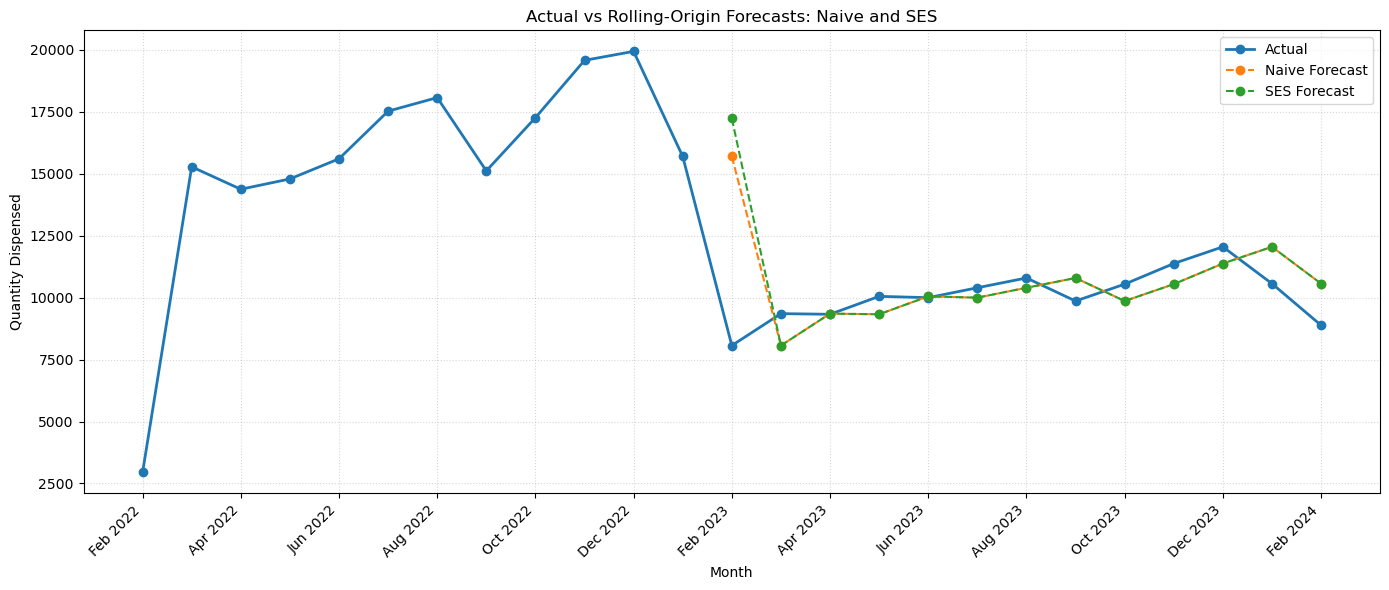

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Prepare monthly data
monthly = monthly.sort_index()

# Store rolling-origin forecasts
results = []

initial_train_size = 12

for i in range(initial_train_size, len(monthly)):

    train = monthly.iloc[:i]
    actual = monthly.iloc[i]

    # Naive forecast: previous month's actual value
    naive_forecast = train.iloc[-1]

    # Simple Exponential Smoothing
    ses_fit = SimpleExpSmoothing(
        train,
        initialization_method="estimated"
    ).fit(
        optimized=True,
        method="L-BFGS-B",
        minimize_kwargs={
            "options": {
                "maxiter": 5000,
                "ftol": 1e-10
            }
        }
    )

    ses_forecast = ses_fit.forecast(1).iloc[0]

    converged = ses_fit.mle_retvals.get('success', None)

    results.append({
        'Date': monthly.index[i],
        'Actual': actual,
        'Naive Forecast': naive_forecast,
        'SES Forecast': ses_forecast,
        'SES Converged': converged
    })

# Convert results into DataFrame
rolling_results = pd.DataFrame(results).set_index('Date')
# print(rolling_results[
#     ['Actual', 'Naive Forecast', 'SES Forecast', 'SES Converged']
# ])

# Calculate and display MAE
mae_naive = (
    rolling_results['Actual'] -
    rolling_results['Naive Forecast']
).abs().mean()

mae_ses = (
    rolling_results['Actual'] -
    rolling_results['SES Forecast']
).abs().mean()

print(f"Naive MAE: {mae_naive:.2f}")
print(f"SES MAE:   {mae_ses:.2f}")

# Ensure datetime index
dates = pd.to_datetime(rolling_results.index)
print(rolling_results.tail())

# Ensure both indexes are datetime indexes
monthly.index = pd.to_datetime(monthly.index)
rolling_results.index = pd.to_datetime(rolling_results.index)

# Use integer positions for the complete monthly series
x = np.arange(len(monthly))

# Map each rolling forecast date to its position in monthly
forecast_positions = monthly.index.get_indexer(rolling_results.index)

if (forecast_positions < 0).any():
    raise ValueError("Some rolling forecast dates are not in the monthly index.")

fig, ax = plt.subplots(figsize=(14, 6))

# Actual values: use the original monthly series
ax.plot(
    x,
    monthly.values,
    marker='o',
    label='Actual',
    linewidth=2
)

# Forecast values: use the positions of their forecast dates
ax.plot(
    forecast_positions,
    rolling_results['Naive Forecast'].values,
    marker='o',
    linestyle='--',
    label='Naive Forecast'
)

ax.plot(
    forecast_positions,
    rolling_results['SES Forecast'].values,
    marker='o',
    linestyle='--',
    label='SES Forecast'
)

# Show date labels at the corresponding monthly positions
tick_positions = np.arange(len(monthly))
tick_labels = monthly.index.strftime('%b %Y')

ax.set_xticks(tick_positions[::2])
ax.set_xticklabels(tick_labels[::2], rotation=45, ha='right')

ax.set_xlabel('Month')
ax.set_ylabel('Quantity Dispensed')
ax.set_title('Actual vs Rolling-Origin Forecasts: Naive and SES')

ax.grid(axis='x', which='major', linestyle=':', alpha=0.5)
ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
ses_parameters = []

for i in range(initial_train_size, len(monthly)):
    train = monthly.iloc[:i]

    ses_fit = SimpleExpSmoothing(
        train,
        initialization_method="estimated"
    ).fit(
        optimized=True,
        method="L-BFGS-B",
        minimize_kwargs={
            "options": {"maxiter": 5000, "ftol": 1e-10}
        }
    )

    ses_parameters.append({
        "Forecast Date": monthly.index[i],
        "Alpha": ses_fit.params["smoothing_level"],
        "Naive Forecast": train.iloc[-1],
        "SES Forecast": ses_fit.forecast(1).iloc[0],
        "Optimization success": ses_fit.mle_retvals["success"],
        "Objective value": ses_fit.mle_retvals["fun"]
    })

ses_parameters_df = pd.DataFrame(ses_parameters).set_index("Forecast Date")

print(ses_parameters_df.round(4))

                Alpha  Naive Forecast  SES Forecast  Optimization success  \
Forecast Date                                                               
2023-02-28     0.5698         15702.0    17234.6955                  True   
2023-03-31     1.0000          8068.0     8068.0001                  True   
2023-04-30     1.0000          9356.0     9356.0000                  True   
2023-05-31     1.0000          9330.0     9330.0000                  True   
2023-06-30     1.0000         10054.0    10054.0000                  True   
2023-07-31     1.0000         10001.0    10001.0000                  True   
2023-08-31     1.0000         10401.0    10401.0000                  True   
2023-09-30     1.0000         10796.0    10796.0000                  True   
2023-10-31     1.0000          9865.0     9865.0000                  True   
2023-11-30     1.0000         10546.0    10546.0000                  True   
2023-12-31     1.0000         11379.0    11379.0000                  True   